# 12A — Functional movement transfer

**Part 1 · Research question (Q1).** Does modelling the whole Combine acceleration–speed function a_C(v) retain transferable athlete-level information that scalar band features lose — and where along the speed axis does transfer sit?

**Part 2 · Declared hypotheses.** *Primary:* A2 (M1 + fold-fitted FPCA scores of a_C(v)) lowers the held-out athlete-mean squared error of the NFL τ-quantile function a_N(v) (12C frozen estimator) vs A0 (M1 + scalar band accelerations), on identical athletes. *Secondary:* A1 (P-spline coefficients), A4 (hierarchical, training-only shrinkage) and the function-on-function framework itself vs M1; the pointwise transfer profile; phase–amplitude structure of speed–time curves (exploratory).

**Fixed rules.** Shared speed range of 12.0 only; each athlete scored on ITS supported bins (equal athlete weight); one interior gap ≤ 1 bin bridged (counted); no extrapolation; every cross-athlete quantity (FPCA, NFL FPCA, shrinkage parameters, ridge penalty) from training athletes of the fold. The spline penalty is chosen by Combine repeat-attempt agreement (no NFL value). Registration never discards timing: the warp IS the phase result.

**Prerequisites.** 12.0 and 12C (its target freeze defines a_N) in the same `RUN_MODE` — the notebook stops otherwise.

In [1]:
RUN_MODE = 'full'
SEED = 20261015
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
MEMORY_BUDGET_GB = 3.0
RUN_ELASTIC = True            # SRSF dynamic-programming alignment (exploratory; ~0.1 s per attempt per iteration)
ELASTIC_MAX_ATTEMPTS = 600    # deterministic cap (attempts ordered by a hash of seq_id)
ELASTIC_WINDOW_S = 3.0        # common time window from onset

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import ResearchStore
from nflbdb.research.advanced_movement.m11 import combine_drills as cd
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import evaluation as ev
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m12 import advanced_evaluation as ae
from nflbdb.research.advanced_movement.m12 import config as m12c
from nflbdb.research.advanced_movement.m12 import distributional_capacity as dc
from nflbdb.research.advanced_movement.m12 import figures as fg
from nflbdb.research.advanced_movement.m12 import foundation as fd
from nflbdb.research.advanced_movement.m12 import functional_movement as fm
from nflbdb.research.advanced_movement.m12 import reporting as rp
from nflbdb.research.advanced_movement.m12 import synthesis as sy
from nflbdb.research.advanced_movement.m12 import validation as v12

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ResearchStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m12c.M12Config().for_mode(controls)
S = src.M11Sources(cfg, store, m11c.M11Config().for_mode(controls))
D = fd.M12Data(store, C, S)
PROV = m12c.provenance('12A', controls, C)
W = store.write_frame
MAN = fd.check_foundation(store, C)
FREEZE = dc.read_freeze(store)              # dependency gate: 12C must have frozen its target
BINS = FREEZE['shared_bins']
VMID = ae.mids(ae.speed_edges(C))[BINS]
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f"**Run mode: `{controls.run_mode}`** ({label}) · config `{C.hash()}` · NFL function = 12C {FREEZE['estimator']} at τ = {FREEZE['tau']} · {len(BINS)} shared bins"))
checks = v12.run_all((*v12.CHECKS_GENERAL, *v12.CHECKS_FUNCTIONAL))
display(checks)
v12.assert_all_passed(checks)

**Run mode: `full`** (FULL) · config `c2903a12f8449fa2` · NFL function = 12C C3_pooled at τ = 0.9 · 12 shared bins

check,status,detail
str,str,str
"""grouped_folds_and_leakage""","""PASS""","""athlete-grouped folds enforced…"
"""block_sees_training_only""","""PASS""","""fold-fitted blocks receive one…"
"""common_cohort_pairing""","""PASS""","""every model of a ladder is sco…"
"""bootstrap_unit_and_seed""","""PASS""","""athlete bootstrap deterministi…"
"""checkpoint_resume_safety""","""PASS""","""completion gate blocks partial…"
…,…,…
"""spline_basis_and_support""","""PASS""","""B-spline partition of unity, z…"
"""fpca_recovery_and_isolation""","""PASS""","""FPCA recovers planted componen…"
"""combine_curve_interpolation""","""PASS""","""Combine a(v) at bin mid-speeds…"


## Part 3–4 · Data, eligibility and functional definitions

Cohort: linked athletes with ≥ 60 % of the shared bins supported in both domains (`elig_12A`). a_C(v): frame-weighted mean rising-phase acceleration per bin over the athlete's forty attempts. a_N(v): the 12C frozen estimator from all the athlete's games. Units yd/s² against yd/s.

In [3]:
reg = D.m12('m12_cohort_registry')
off, athf = D.officials(), D.athlete_features()
POS = {int(i): p for i, p in zip(off['nfl_id'].to_list(), off['position_group'].to_list())}
ids = np.array(sorted(reg.filter(pl.col('elig_12A'))['nfl_id'].to_list()))
curves = D.m12('m12_combine_curves')
ids_c, Mc, bridged = fm.combine_athlete_matrix(curves, BINS, C, ids)
att_meta, A = fm.combine_attempt_matrix(curves.filter(pl.col('nfl_id').is_in(ids.tolist())), BINS, C)
h = D.hist_athletes(ids.tolist())
cubes = dc.build_cubes(h, POS, C)
del h
Fn = dc.curves(cubes, None, [FREEZE['tau']], C, FREEZE['lambda_c2'], C.env_boot, C.seed)[FREEZE['tau']][FREEZE['estimator']]
Y = np.array([Fn[int(i)][BINS] if int(i) in Fn else np.full(len(BINS), np.nan) for i in ids])
display(ae.memory_plan([{'item': 'Combine athlete curves', 'n_rows': Mc.shape[0], 'n_cols': Mc.shape[1]}, {'item': 'attempt curves', 'n_rows': A.shape[0], 'n_cols': A.shape[1]},
                        {'item': 'NFL functions', 'n_rows': Y.shape[0], 'n_cols': Y.shape[1]}], MEMORY_BUDGET_GB))
fman = D.m12('m12_fold_manifest').select('nfl_id', 'fold')
cw = cd.wide(athf, ['forty.band_2_4_mean_accel', 'forty.band_4_6_mean_accel', 'forty.band_6_8_mean_accel'])
# rows MUST align with Y (built in sorted ids order): joins do not guarantee order, so sort afterwards
df = pl.DataFrame({'nfl_id': ids}).join(off, on='nfl_id', how='left').join(cw, on='nfl_id', how='left').join(fman, on='nfl_id', how='left').sort('nfl_id')
assert (df['nfl_id'].to_numpy() == ids).all()
keep = (df['fold'].is_not_null() & pl.Series(np.isfinite(Y).sum(1) >= max(3, len(BINS) // 2))).to_numpy()
df, Y = df.filter(pl.Series(keep)), Y[keep]
ids = df['nfl_id'].to_numpy()
print(f'{ids.size} athletes · {A.shape[0]} attempts · bridged interior bins: {int(bridged.sum())} over {int((bridged > 0).sum())} athletes')

c:\Users\myben\.conda\envs\nfl\lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:212: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(M, 0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:213: RuntimeWarning: Degrees of freedom <= 0 for slice.
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(S2, 0), 0.0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:213: RuntimeWarning: Mean of empty slice
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(S2, 0), 0.0)


item,n_rows,n_cols,est_mb,on_disk_mb,note,budget_mb,within_budget
str,i64,i64,f64,null,str,f64,bool
"""Combine athlete curves""",310,12,0.0,null,"""""",3000.0,true
"""attempt curves""",586,12,0.1,null,"""""",3000.0,true
"""NFL functions""",310,12,0.0,null,"""""",3000.0,true


310 athletes · 586 attempts · bridged interior bins: 44 over 34 athletes


## Part 5–6 · Baselines and functional representations

M1 (officials) · A0 = M1 + three band accelerations (scalar) · A1 = M1 + P-spline coefficients (λ by repeat-attempt agreement) · A2 = M1 + FPCA scores (fold-fitted) · A4 = M1 + FPCA of hierarchical (shrunk) curves (training-only shrinkage) · controls: A2 with curves shuffled within position, M1 + random Gaussian scores of the same dimension. The NFL side is modelled through its own training-fold FPCA (function-on-function regression); a pointwise (one ridge per bin) version is a sensitivity.

In [4]:
Bsp, lo_, hi_ = fm.spline_basis_for(BINS, C)
LAM_S, lam_tab = fm.choose_lambda_repeat(att_meta, A, Bsp, set(ids.tolist()), C.spline_lambdas)
W(lam_tab, 'm12a_spline_lambda')
display(lam_tab)
rng = np.random.default_rng(C.seed)
posa = np.array([POS.get(int(i), '?') for i in ids_c])
perm = np.arange(ids_c.size)
for p in np.unique(posa):
    ix = np.flatnonzero(posa == p)
    perm[ix] = rng.permutation(ix)
Mshuf = Mc[perm]
f_full = fm.FPCA.fit(Mc, C.fpca_var, C.fpca_max_k)
KD = f_full.phi.shape[1] if f_full is not None else 2

def rand_block(a_ids):
    R = np.random.default_rng(C.seed + 5).standard_normal((len(a_ids), KD))
    return lambda train: pl.DataFrame({f'r{k}': R[:, k] for k in range(KD)})

BANDS = ['forty.band_2_4_mean_accel', 'forty.band_4_6_mean_accel', 'forty.band_6_8_mean_accel']
MODELS = {'M1': ae.Model(list(ae.M1_COLS)), 'A0': ae.Model([*ae.M1_COLS, *BANDS]),
          'A1': ae.Model(list(ae.M1_COLS), factory=lambda a: fm.spline_block(a, ids_c, Mc, Bsp, LAM_S)),
          'A2': ae.Model(list(ae.M1_COLS), factory=lambda a: fm.fpca_block(a, ids_c, Mc, C)),
          'A4': ae.Model(list(ae.M1_COLS), factory=lambda a: fm.hierarchical_block(a, att_meta, A, POS, C)),
          'CTRL_shuffled': ae.Model(list(ae.M1_COLS), factory=lambda a: fm.fpca_block(a, ids_c, Mshuf, C)),
          'CTRL_random': ae.Model(list(ae.M1_COLS), factory=rand_block)}
res = fm.functional_oof(df, Y, MODELS, C, C.seed, mode='fpc')
COMPS = [('A2', 'A0'), ('A0', 'M1'), ('A1', 'M1'), ('A2', 'M1'), ('A4', 'M1'), ('A2', 'A1'), ('CTRL_shuffled', 'M1'), ('CTRL_random', 'M1')]
cmp = fm.compare_functional(res, COMPS, C, C.seed).with_columns(pl.lit('fof').alias('mode'))
res_pw = fm.functional_oof(df, Y, {k: MODELS[k] for k in ('M1', 'A0', 'A2')}, C, C.seed, mode='pointwise')
cmp_pw = fm.compare_functional(res_pw, [('A2', 'A0'), ('A0', 'M1'), ('A2', 'M1')], C, C.seed).with_columns(pl.lit('pointwise').alias('mode'))
CMP = pl.concat([cmp, cmp_pw], how='diagonal_relaxed')
W(CMP, 'm12a_compare')
with pl.Config(tbl_rows=-1, tbl_width_chars=260):
    display(CMP.select('mode', 'model', 'reference', 'n_athletes', 'mse_ref', 'mse_model', 'delta_mse', 'delta_lo', 'delta_hi', 'delta_pct', 'spearman_level_model', 'verdict'))

lambda,n_pairs,repeat_mse
f64,i64,f64
0.1,276,0.85044
1.0,276,0.835903
10.0,276,0.907975
100.0,276,1.015281


C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\functional_movement.py:328: RuntimeWarning: Mean of empty slice
  mean_i[int(i)] = np.nanmean(rows, 0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\functional_movement.py:365: RuntimeWarning: Mean of empty slice
  m_ = np.nanmean(rows, 0)


mode,model,reference,n_athletes,mse_ref,mse_model,delta_mse,delta_lo,delta_hi,delta_pct,spearman_level_model,verdict
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,str
"""fof""","""A2""","""A0""",310,0.066368,0.06656,-0.000192,-0.000702,0.000279,-0.289457,0.963717,"""inconclusive"""
"""fof""","""A0""","""M1""",310,0.066307,0.066368,-0.000061,-0.000666,0.000505,-0.092298,0.963741,"""inconclusive"""
"""fof""","""A1""","""M1""",310,0.066307,0.066146,0.00016,-0.000691,0.000959,0.241516,0.964515,"""inconclusive"""
"""fof""","""A2""","""M1""",310,0.066307,0.06656,-0.000253,-0.000745,0.000199,-0.382023,0.963717,"""inconclusive"""
"""fof""","""A4""","""M1""",310,0.066307,0.06685,-0.000543,-0.000902,-0.000205,-0.81907,0.962666,"""reversed"""
"""fof""","""A2""","""A1""",310,0.066146,0.06656,-0.000413,-0.001161,0.000272,-0.625048,0.963717,"""inconclusive"""
"""fof""","""CTRL_shuffled""","""M1""",310,0.066307,0.066357,-0.000051,-0.000958,0.000907,-0.076247,0.962864,"""inconclusive"""
"""fof""","""CTRL_random""","""M1""",310,0.066307,0.067033,-0.000726,-0.001232,-0.000259,-1.095118,0.963337,"""reversed"""
"""pointwise""","""A2""","""A0""",310,0.05203,0.052427,-0.000396,-0.000985,0.000182,-0.762031,0.963467,"""inconclusive"""


## Part 7 · Where along the speed axis does transfer sit? — pointwise effects, positions, hierarchical repeat prediction, FPC reliability

In [5]:
pw = pl.concat([fm.pointwise_effect(res, a_, b_, VMID, C, C.seed).with_columns(pl.lit(f'{a_} vs {b_}').alias('comparison')) for a_, b_ in (('A2', 'A0'), ('A2', 'M1'), ('A0', 'M1'))])
W(pw, 'm12a_pointwise')
bypos = []
for p in sorted(set(res.positions.tolist())):
    m = res.positions == p
    if m.sum() < C.min_athletes // 2:
        continue
    a_, b_ = fm.athlete_mse(res.Y[m], res.preds['A0'][m]), fm.athlete_mse(res.Y[m], res.preds['A2'][m])
    bypos.append({'position_group': p, **ae.paired_metric_diff(a_, b_, max(200, C.n_boot // 5), C.seed)})
bypos = pl.DataFrame(bypos, infer_schema_length=None)
W(bypos, 'm12a_by_position')
rpt = fm.repeat_prediction(att_meta, A, POS)
W(rpt, 'm12a_hierarchical_repeat')
rp_sum = ae.paired_metric_diff(rpt['mse_raw'].to_numpy(), rpt['mse_pooled'].to_numpy(), max(200, C.n_boot // 5), C.seed) if rpt.height else {}
_, comps_h = fm.hierarchical_curves(att_meta, A, POS)
W(comps_h, 'm12a_hierarchical_components')
fpc_rel = []
if f_full is not None:
    am = att_meta.with_row_index('_r')
    pairs = [(g.sort('attempt_order')['_r'][0], g.sort('attempt_order')['_r'][1]) for _, g in am.partition_by(['nfl_id'], as_dict=True).items() if g.height >= 2]
    S1, S2 = f_full.scores(A[[a for a, _ in pairs]]), f_full.scores(A[[b for _, b in pairs]])
    for k in range(S1.shape[1]):
        fpc_rel.append({'component': k + 1, 'variance_share_cum': float(f_full.var_share[k]), **ae.split_reliability(S1[:, k], S2[:, k], max(200, C.n_boot // 5), C.seed)})
fpc_rel = pl.DataFrame(fpc_rel, infer_schema_length=None)
W(fpc_rel, 'm12a_fpc_reliability')
display(bypos)
display(pl.DataFrame([rp_sum]) if rp_sum else Markdown('_no athletes with repeats_'))
display(fpc_rel)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\functional_movement.py:342: RuntimeWarning: Mean of empty slice
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(sigma2 / np.where(Nn > 0, Nn, np.nan), 0), 0.0)


position_group,n_athletes,a,b,diff,lo,hi
str,i64,f64,f64,f64,f64,f64
"""DB""",75,0.058235,0.057676,0.000559,-0.000068,0.0014
"""DL""",75,0.087087,0.087233,-0.000146,-0.001006,0.000872
"""OL""",63,0.043891,0.044239,-0.000348,-0.001576,0.000908
"""TE""",25,0.1164,0.115727,0.000673,-0.000612,0.001747
"""WR""",72,0.055552,0.056739,-0.001187,-0.002501,-0.000033


n_athletes,a,b,diff,lo,hi
i64,f64,f64,f64,f64,f64
276,0.878537,0.878537,0.0,0.0,0.0


component,variance_share_cum,n_athletes,r_half,rho_half,reliability,rel_lo,rel_hi
i64,f64,i64,f64,f64,f64,f64,f64
1,0.653557,276,0.617156,0.745871,0.763261,0.643235,0.858084
2,0.858792,276,0.397986,0.456668,0.56937,0.438107,0.700778
3,0.910991,276,-0.005321,0.177222,-0.010699,-0.378691,0.309166


## Part 7b · Elastic functional alignment of speed–time curves (exploratory)

Window [0, `ELASTIC_WINDOW_S`] s from onset (attempts covering the window only). Landmark registration on the first-crossing times of 4 / 6 / 8 yd/s, and SRSF dynamic-programming alignment to an iterated mean template. Reported: phase distance ‖√γ′ − 1‖ (timing), amplitude distance (shape after alignment), their repeat-attempt ICC, their redundancy with the official forty / 10-yd split, and the phase / amplitude split of stopwatch-twin differences.

In [6]:
pa, el_icc, el_red, twin_dec = pl.DataFrame(), pl.DataFrame(), pl.DataFrame(), pl.DataFrame()
if RUN_ELASTIC:
    st = D.m12('m12_combine_speed_time')
    meta_v, V, g = fm.speed_time_matrix(st, ELASTIC_WINDOW_S, C)
    order = meta_v.with_row_index('_r').with_columns(pl.col('seq_id').hash(C.seed).alias('_h')).sort('_h').head(ELASTIC_MAX_ATTEMPTS)['_r'].to_numpy()
    order = np.sort(order)
    meta_v, V = meta_v[order], V[order]
    L = fm.landmarks(V, g)
    Lref = np.nanmean(L, 0)
    Vl = fm.landmark_register(V, g, L, Lref)
    Va, G, tmpl = fm.elastic_align(V, g)
    pa = pl.concat([meta_v, fm.phase_amplitude(V, Va, G, tmpl, g), pl.DataFrame({'t_to_4': L[:, 0], 't_to_6': L[:, 1], 't_to_8': L[:, 2]})], how='horizontal')
    long_pa = pa.unpivot(index=['seq_id', 'nfl_id'], on=['phase_distance', 'amplitude_distance', 'warp_mid_shift_s', 't_to_4', 't_to_6', 't_to_8'], variable_name='feature', value_name='value').drop_nulls()
    el_icc = ev.repeatability_table(long_pa, seed=C.seed)
    am = pa.group_by('nfl_id').agg([pl.col(k).mean() for k in ('phase_distance', 'amplitude_distance', 'warp_mid_shift_s', 't_to_4', 't_to_6', 't_to_8')]).join(off, on='nfl_id')
    el_red = pl.DataFrame([{'feature': k, **ev.stopwatch_redundancy(am, k)} for k in ('phase_distance', 'amplitude_distance', 'warp_mid_shift_s', 't_to_4', 't_to_8')])
    tw = D.twins()
    ath = {int(i): np.flatnonzero(meta_v['nfl_id'].to_numpy() == i) for i in np.unique(meta_v['nfl_id'].to_numpy())}
    rows = []
    for r in tw.iter_rows(named=True):
        a_, b_ = ath.get(int(r['nfl_id_a'])), ath.get(int(r['nfl_id_b']))
        if a_ is None or b_ is None or not a_.size or not b_.size:
            continue
        Ga, Gb = G[a_].mean(0), G[b_].mean(0)
        Vaa, Vbb = Va[a_].mean(0), Va[b_].mean(0)
        dt_ = g[1] - g[0]
        ph_, amp_ = float(np.sqrt(np.sum((Ga - Gb) ** 2) * dt_)), float(np.sqrt(np.sum((Vaa - Vbb) ** 2) * dt_))
        raw = float(np.sqrt(np.sum((V[a_].mean(0) - V[b_].mean(0)) ** 2) * dt_))
        rows.append({'pair_id': r['pair_id'], 'position_group': r['position_group'], 'd_forty': r['d_forty'], 'phase_diff_s': ph_, 'amplitude_diff': amp_, 'raw_diff': raw})
    twin_dec = pl.DataFrame(rows)
W(pa, 'm12a_phase_amplitude')
W(el_icc, 'm12a_elastic_repeatability')
W(el_red, 'm12a_elastic_redundancy')
W(twin_dec, 'm12a_twin_decomposition')
display(el_icc)
display(el_red)
display(twin_dec.describe() if twin_dec.height else Markdown('_no twin pair with aligned attempts_'))

feature,n_athletes,n_repeat,icc,icc_lo,icc_hi
str,i64,i64,f64,f64,f64
"""amplitude_distance""",388,212,0.148939,0.0,0.955162
"""phase_distance""",388,212,0.35035,0.185769,0.497144
"""t_to_4""",388,211,0.599325,0.383064,0.755852
"""t_to_6""",388,211,0.711677,0.600476,0.797902
"""t_to_8""",388,210,0.916854,0.886604,0.938988
"""warp_mid_shift_s""",388,212,0.360684,0.085533,0.593964


feature,n_athletes,r2_official
str,i64,f64
"""phase_distance""",388,0.007566
"""amplitude_distance""",388,0.012552
"""warp_mid_shift_s""",388,0.021184
"""t_to_4""",387,0.045187
"""t_to_8""",386,0.488486


statistic,pair_id,position_group,d_forty,phase_diff_s,amplitude_diff,raw_diff
str,str,str,f64,f64,f64,f64
"""count""","""2695""","""2695""",2695.0,2695.0,2695.0,2695.0
"""null_count""","""0""","""0""",0.0,0.0,0.0,0.0
"""mean""",null,null,-0.000456,0.180036,0.436983,0.74122
"""std""",null,null,0.020188,0.188141,0.504874,0.794601
"""min""","""55867-55877""","""DB""",-0.03,0.0,0.056366,0.056366
"""25%""",null,null,-0.02,0.073834,0.248146,0.335935
"""50%""",null,null,0.0,0.135657,0.348062,0.537702
"""75%""",null,null,0.02,0.217514,0.503941,0.858254
"""max""","""59004-59278""","""WR""",0.03,1.557455,6.621443,7.019281


## Part 8–9 · Uncertainty, sensitivity and figures

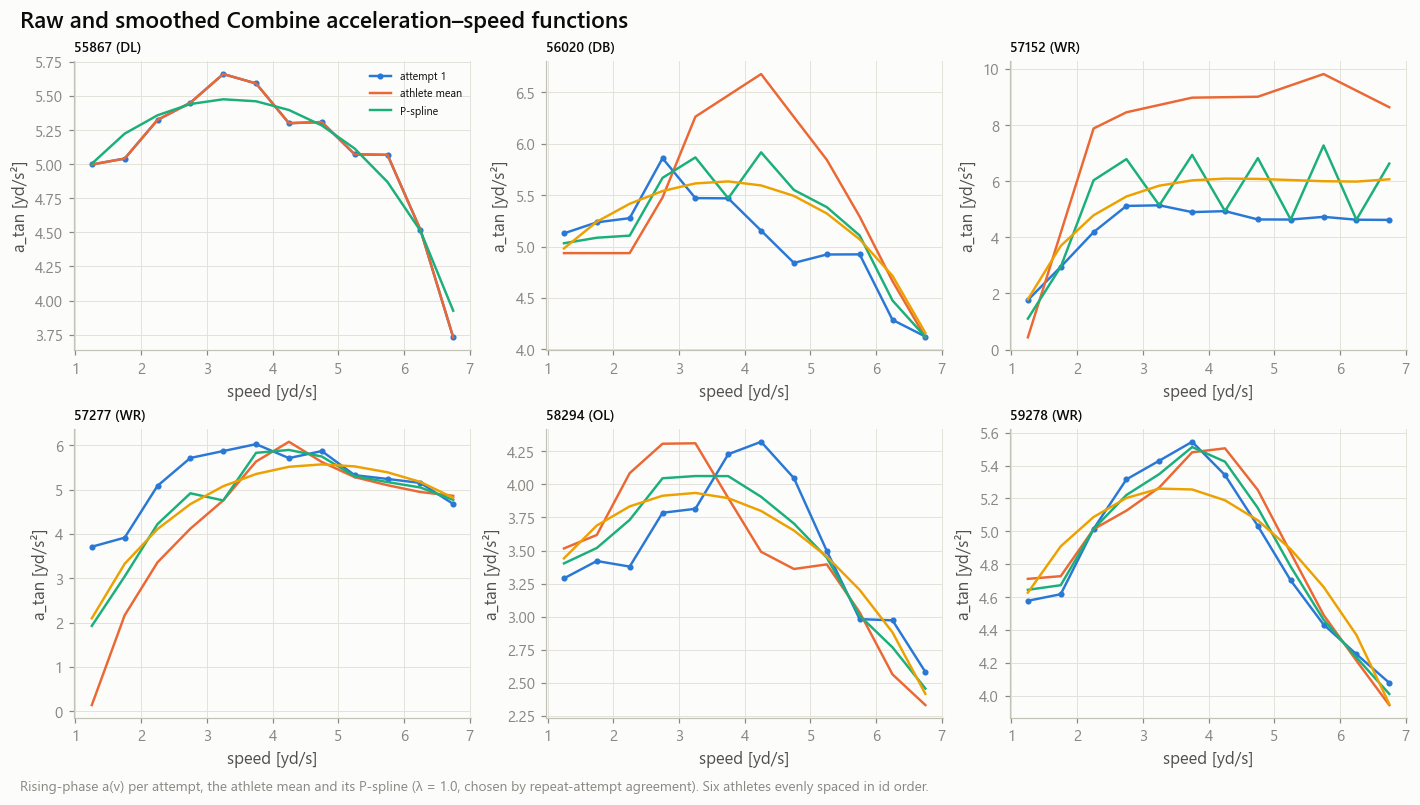

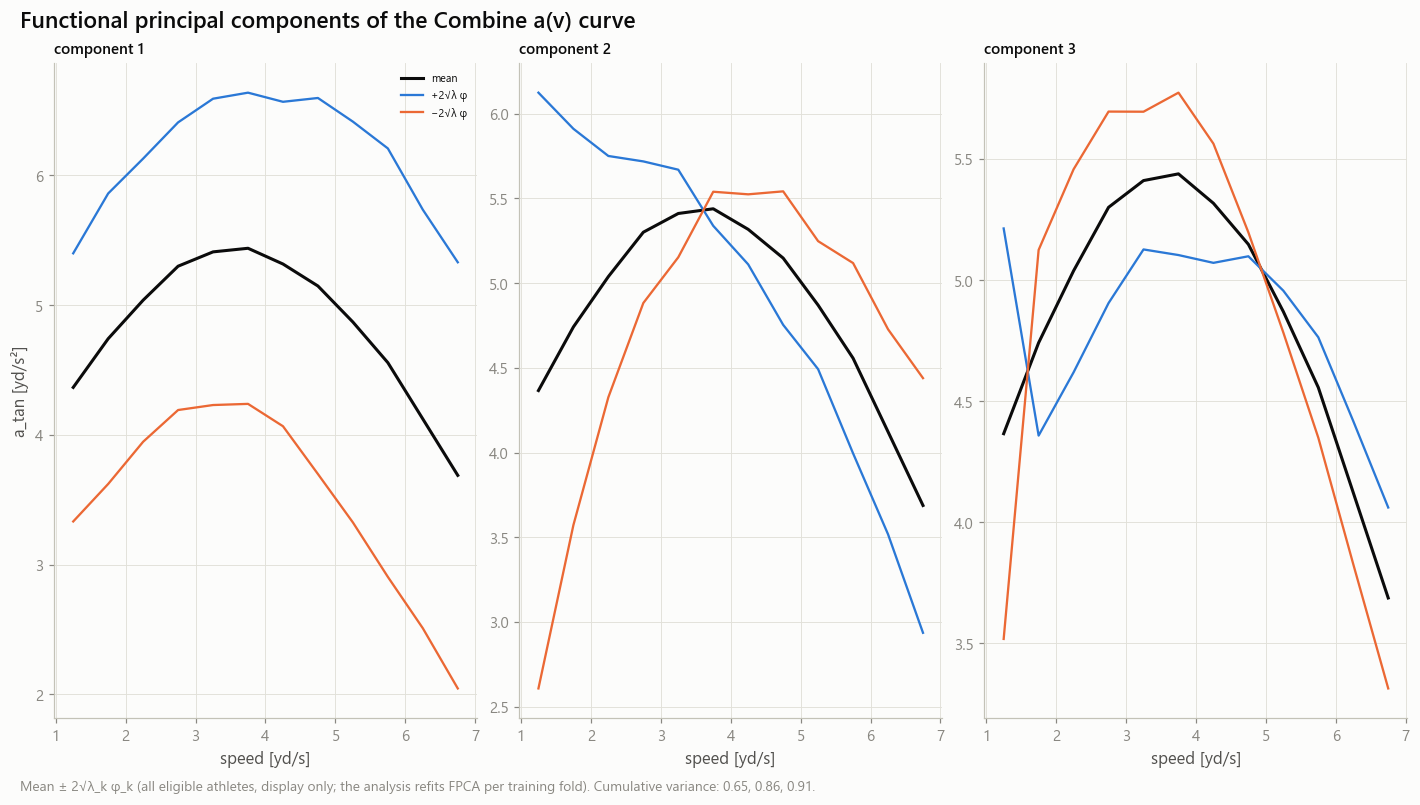

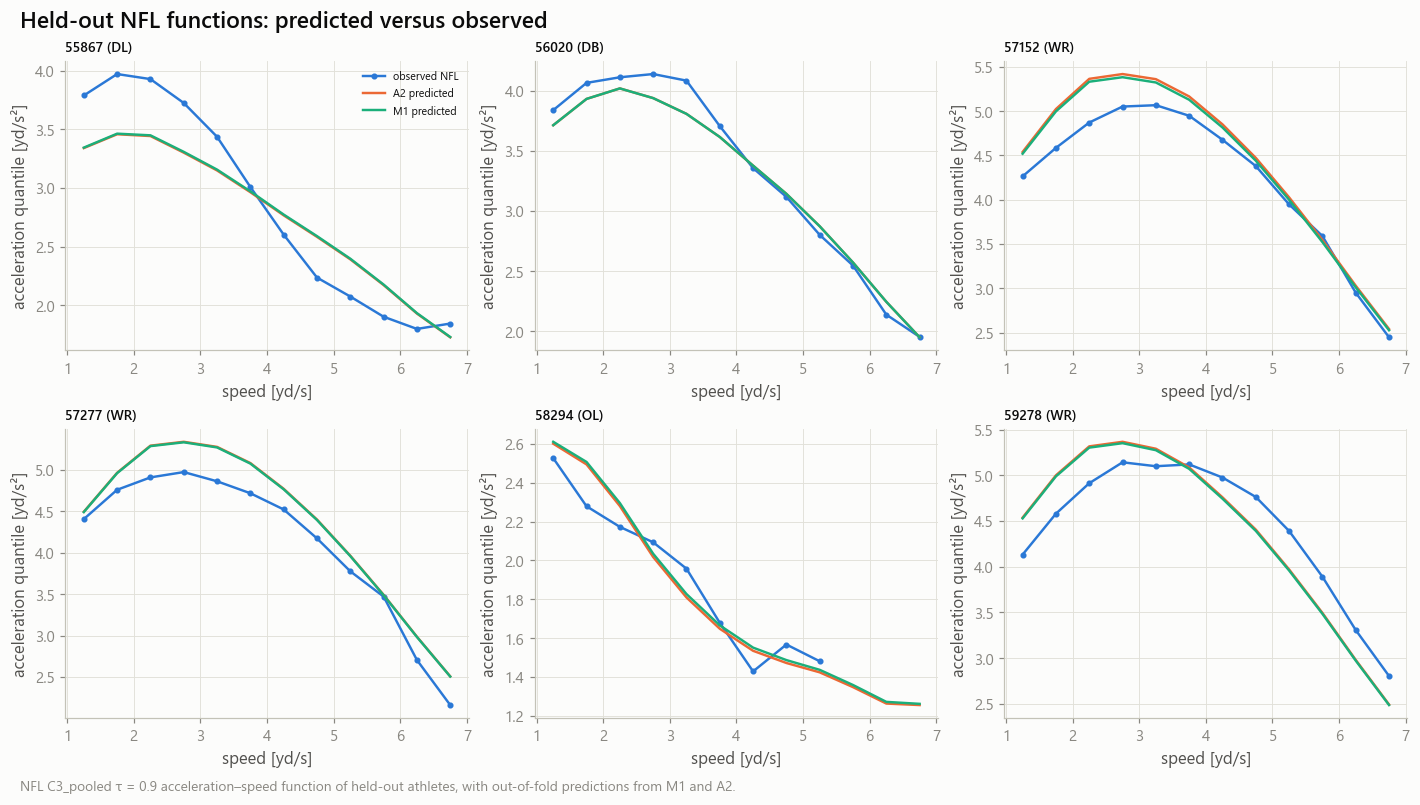

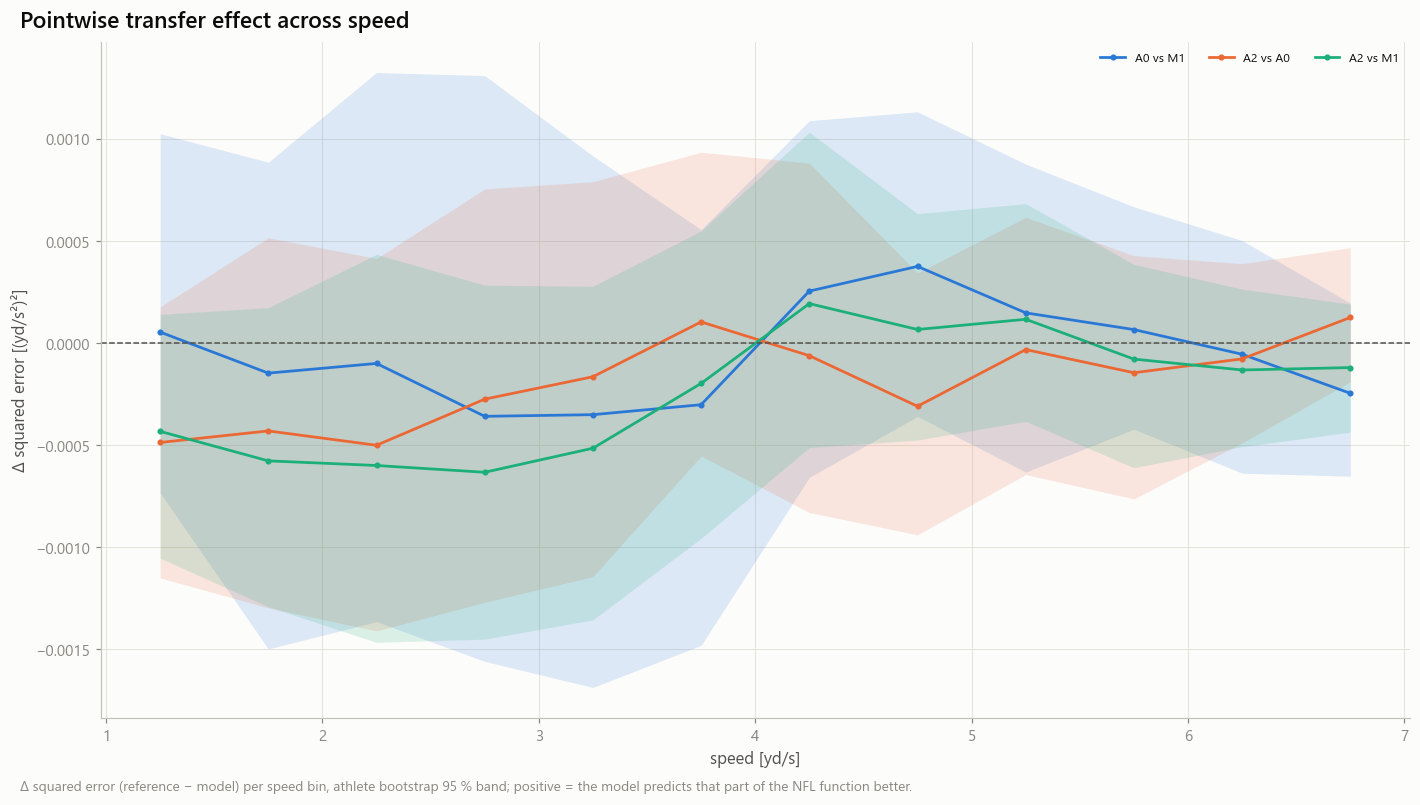

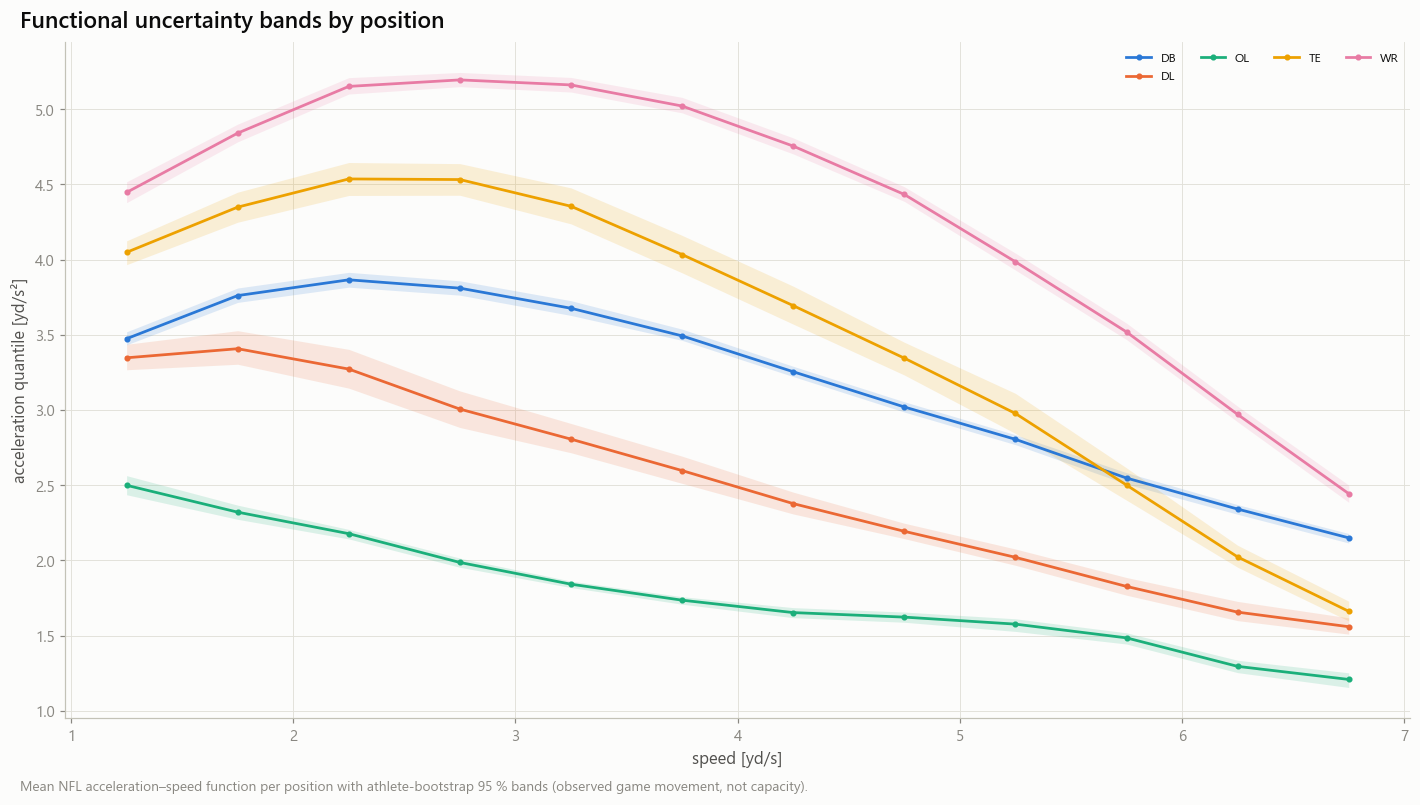

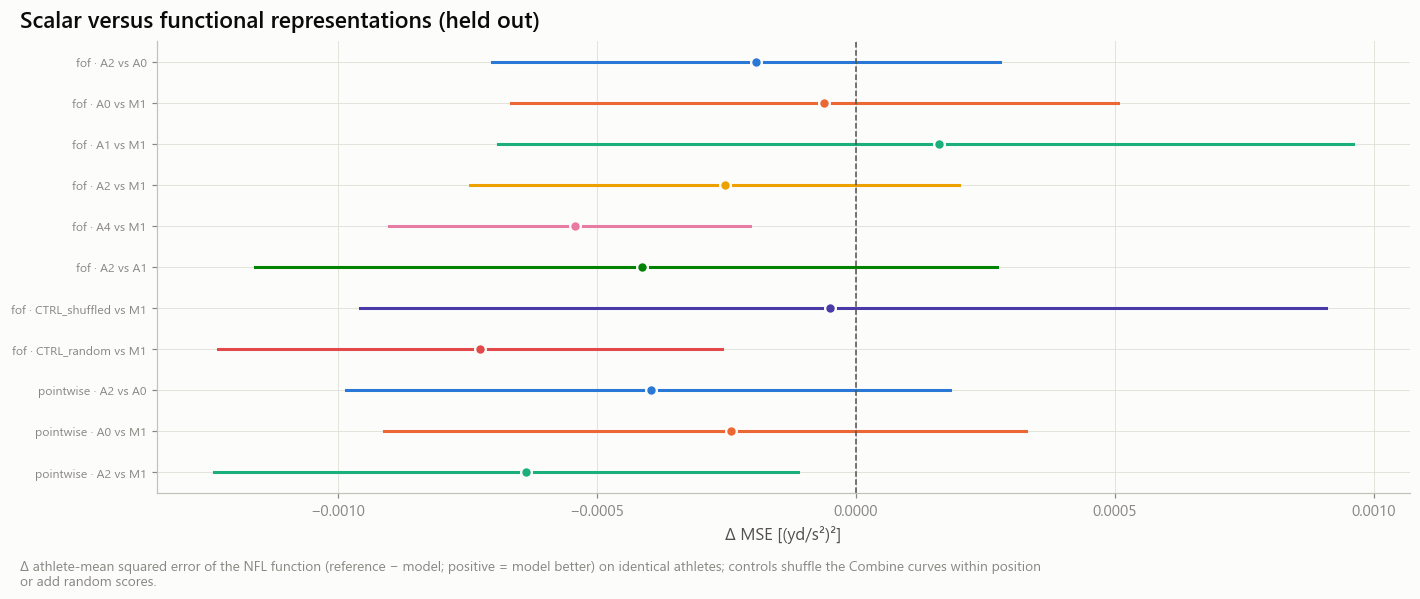

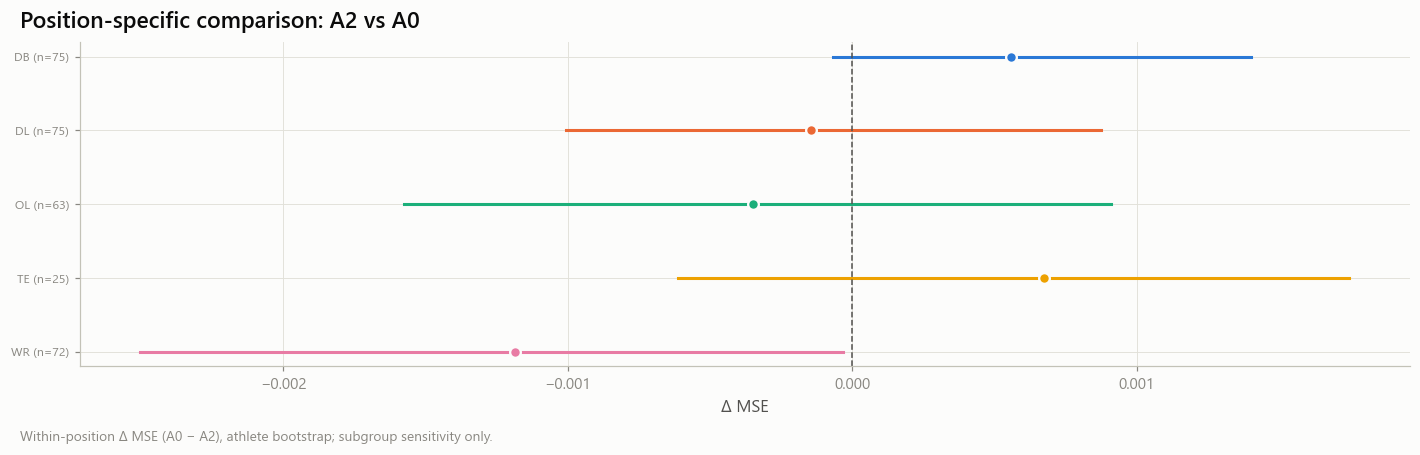

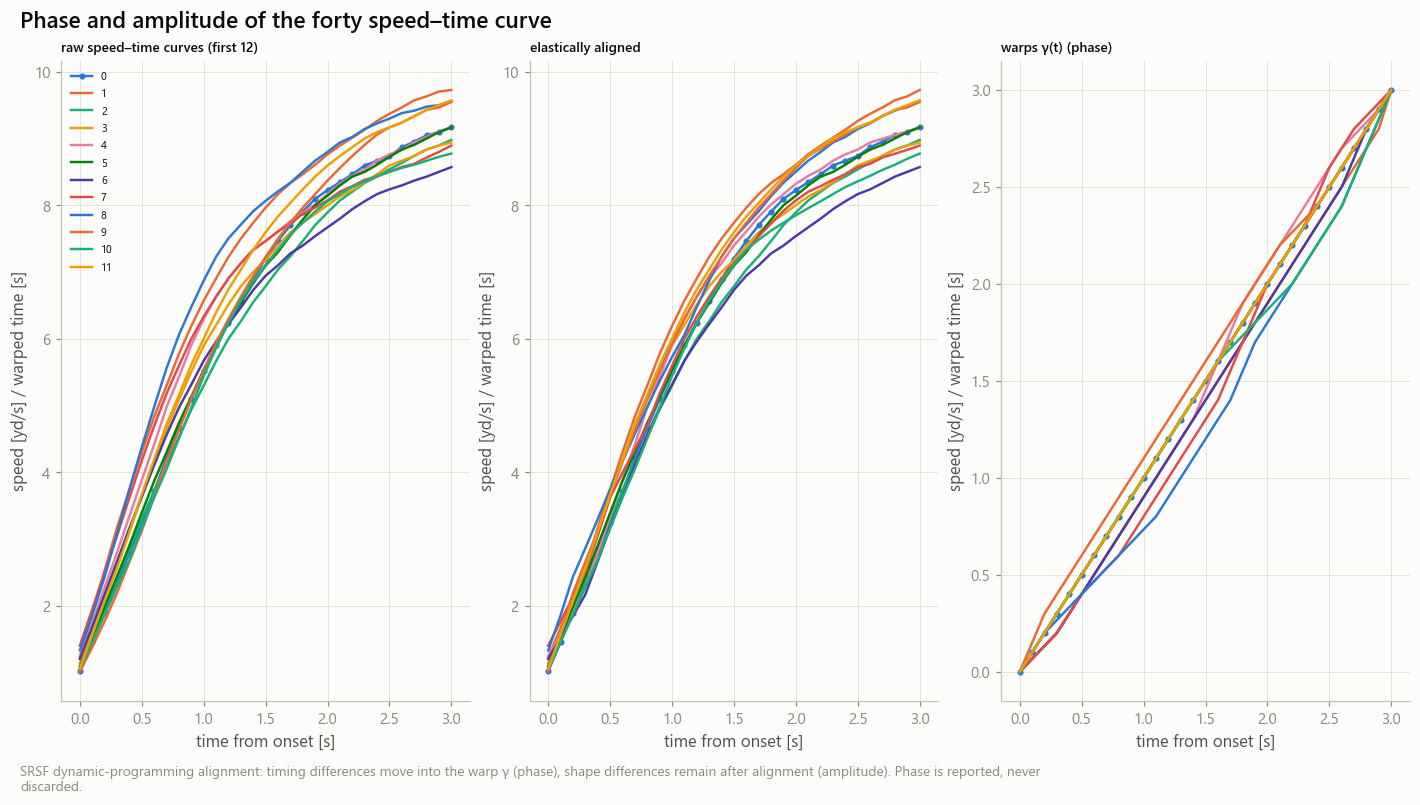

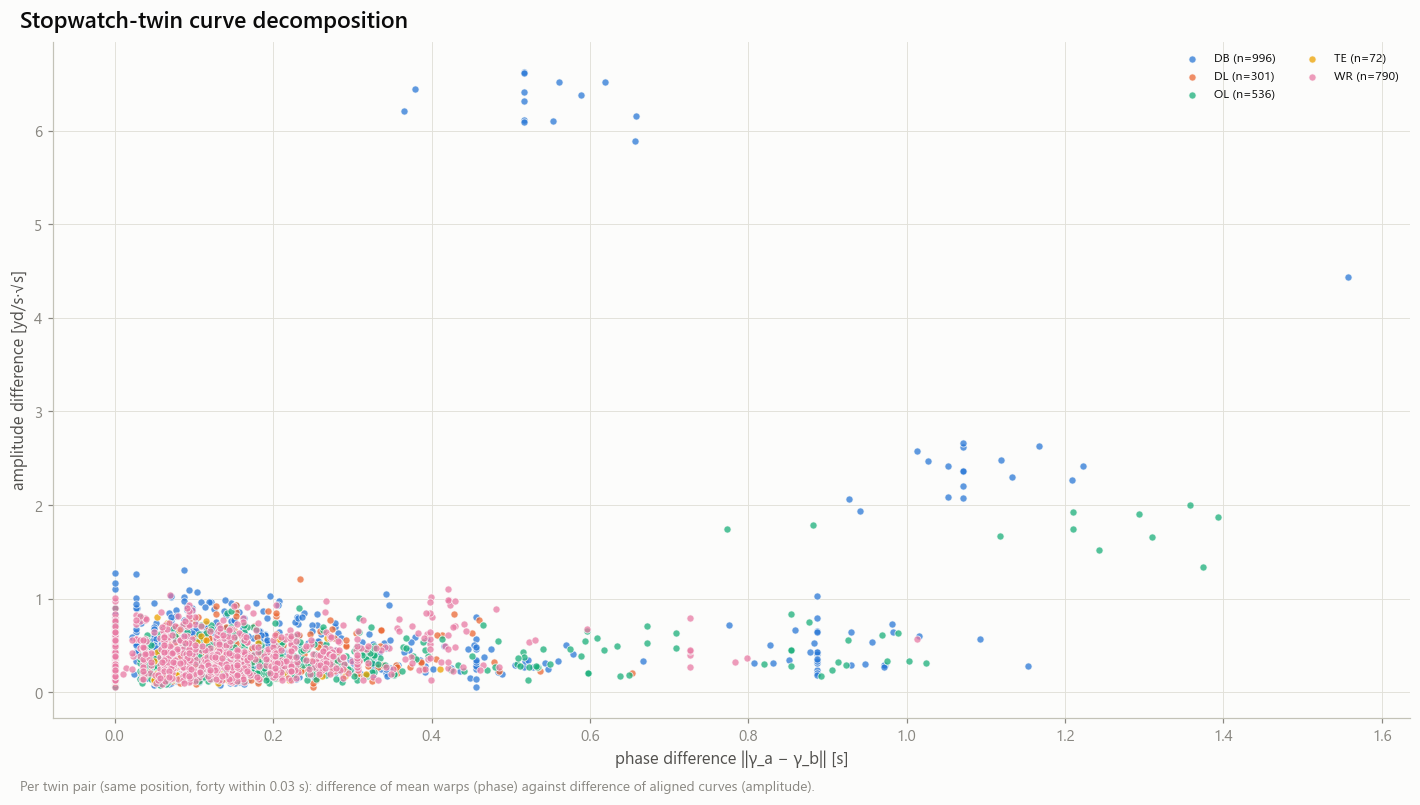

In [7]:
ex = [int(ids_c[k]) for k in np.linspace(0, ids_c.size - 1, 6).astype(int)] if ids_c.size else []
series = []
for i in ex:
    rows_ = np.flatnonzero(att_meta['nfl_id'].to_numpy() == i)
    lines = {f'attempt {k + 1}': A[r] for k, r in enumerate(rows_[:3])}
    k_ = int(np.flatnonzero(ids_c == i)[0])
    lines['athlete mean'] = Mc[k_]
    if np.isfinite(Mc[k_]).sum() >= 4:
        lines['P-spline'] = Bsp @ fm.spline_coefs(Mc[k_][None, :], Bsp, LAM_S)[0]
    series.append({'label': f'{i} ({POS.get(i, "?")})', 'lines': lines})
store.show(fg.fig_curve_examples(VMID, series, 'Raw and smoothed Combine acceleration–speed functions', f'Rising-phase a(v) per attempt, the athlete mean and its P-spline (λ = {LAM_S}, chosen by repeat-attempt agreement). Six athletes evenly spaced in id order.',
                                 'speed [yd/s]', 'a_tan [yd/s²]'), 'AM12_A_01_raw_and_smoothed_functions', {}, publication=True, source='m12_combine_curves')
if f_full is not None:
    store.show(fg.fig_components(VMID, f_full.mean, f_full.phi, f_full.eig, 'Functional principal components of the Combine a(v) curve', f'Mean ± 2√λ_k φ_k (all eligible athletes, display only; the analysis refits FPCA per training fold). Cumulative variance: {", ".join(f"{x:.2f}" for x in f_full.var_share)}.',
                                   'speed [yd/s]', 'a_tan [yd/s²]'), 'AM12_A_02_fpca_components', {}, publication=True, source='m12_combine_curves')
pick = [int(k) for k in np.linspace(0, res.ids.size - 1, 6).astype(int)]
store.show(fg.fig_curve_examples(VMID, [{'label': f'{int(res.ids[k])} ({res.positions[k]})', 'lines': {'observed NFL': res.Y[k], 'A2 predicted': res.preds['A2'][k], 'M1 predicted': res.preds['M1'][k]}} for k in pick],
                                 'Held-out NFL functions: predicted versus observed', f"NFL {FREEZE['estimator']} τ = {FREEZE['tau']} acceleration–speed function of held-out athletes, with out-of-fold predictions from M1 and A2.", 'speed [yd/s]', 'acceleration quantile [yd/s²]'),
           'AM12_A_03_predicted_vs_observed', {}, publication=True, source='m12a (out-of-fold)')
store.show(fg.fig_lines(pw, 'speed_mid', 'delta_se', 'comparison', 'Pointwise transfer effect across speed', 'Δ squared error (reference − model) per speed bin, athlete bootstrap 95 % band; positive = the model predicts that part of the NFL function better.',
                        'speed [yd/s]', 'Δ squared error [(yd/s²)²]', 'lo', 'hi', ref=0.0), 'AM12_A_04_pointwise_effect', {'pointwise': pw}, publication=True, source='m12a_pointwise')
band = []
for p in sorted(set(res.positions.tolist())):
    m = res.positions == p
    if m.sum() < C.min_athletes // 2:
        continue
    Yp = res.Y[m]
    bs = np.random.default_rng(C.seed).integers(0, m.sum(), (200, m.sum()))
    with np.errstate(invalid='ignore'):
        mb = np.array([np.nanmean(Yp[b], 0) for b in bs])
        band += [{'position_group': p, 'speed': float(VMID[k]), 'mean': float(np.nanmean(Yp[:, k])), 'lo': float(np.nanquantile(mb[:, k], 0.025)), 'hi': float(np.nanquantile(mb[:, k], 0.975))} for k in range(len(BINS))]
band = pl.DataFrame(band)
store.show(fg.fig_lines(band, 'speed', 'mean', 'position_group', 'Functional uncertainty bands by position', 'Mean NFL acceleration–speed function per position with athlete-bootstrap 95 % bands (observed game movement, not capacity).',
                        'speed [yd/s]', 'acceleration quantile [yd/s²]', 'lo', 'hi'), 'AM12_A_05_functional_bands', {'bands': band}, source='m12c freeze + m11_envelope_hist')
fp = CMP.with_columns((pl.col('mode') + ' · ' + pl.col('model') + ' vs ' + pl.col('reference')).alias('label'))
store.show(fg.fig_forest(fp, 'label', 'delta_mse', 'delta_lo', 'delta_hi', 'Scalar versus functional representations (held out)', 'Δ athlete-mean squared error of the NFL function (reference − model; positive = model better) on identical athletes; controls shuffle the Combine curves within position or add random scores.',
                         'Δ MSE [(yd/s²)²]', color_by='mode'), 'AM12_A_06_functional_forest', {'compare': fp}, publication=True, source='m12a_compare')
if bypos.height:
    bp = bypos.with_columns((pl.col('position_group') + ' (n=' + pl.col('n_athletes').cast(pl.String) + ')').alias('label'))
    store.show(fg.fig_forest(bp, 'label', 'diff', 'lo', 'hi', 'Position-specific comparison: A2 vs A0', 'Within-position Δ MSE (A0 − A2), athlete bootstrap; subgroup sensitivity only.', 'Δ MSE', color_by='position_group'),
               'AM12_A_07_by_position', {'by_position': bp}, source='m12a_by_position')
if pa.height:
    k0 = int(np.argsort(pa['phase_distance'].to_numpy())[pa.height // 2])
    store.show(fg.fig_curve_examples(g, [{'label': 'raw speed–time curves (first 12)', 'lines': {f'{j}': V[j] for j in range(min(12, V.shape[0]))}},
                                         {'label': 'elastically aligned', 'lines': {f'{j}': Va[j] for j in range(min(12, V.shape[0]))}},
                                         {'label': 'warps γ(t) (phase)', 'lines': {f'{j}': G[j] for j in range(min(12, V.shape[0]))}}],
                                     'Phase and amplitude of the forty speed–time curve', 'SRSF dynamic-programming alignment: timing differences move into the warp γ (phase), shape differences remain after alignment (amplitude). Phase is reported, never discarded.',
                                     'time from onset [s]', 'speed [yd/s] / warped time [s]'), 'AM12_A_08_phase_amplitude', {}, publication=True, source='m12a_phase_amplitude')
if twin_dec.height:
    store.show(fg.fig_scatter(twin_dec, 'phase_diff_s', 'amplitude_diff', 'Stopwatch-twin curve decomposition', 'Per twin pair (same position, forty within 0.03 s): difference of mean warps (phase) against difference of aligned curves (amplitude).',
                              'phase difference ‖γ_a − γ_b‖ [s]', 'amplitude difference [yd/s·√s]'), 'AM12_A_09_twin_decomposition', {'twins': twin_dec}, source='m12a_twin_decomposition')

## Part 10–12 · Conclusions, comparisons for 12G, artifacts, next questions

In [8]:
rm = controls.run_mode
comps = [sy.comparison_row('12A', f"{r['mode']}: {r['model']} vs {r['reference']}", 'Δ MSE of the NFL function', r['delta_mse'], r['delta_lo'], r['delta_hi'], r['n_athletes'],
                           m12c.PHYSICAL_TRANSFER, 'm12a_compare', rm, experiment=1, primary=(r['mode'], r['model'], r['reference']) == ('fof', 'A2', 'A0'))
         for r in CMP.iter_rows(named=True)]
if rp_sum:
    comps.append(sy.comparison_row('12A', 'hierarchical pooling vs raw (attempt 1 → attempt 2)', 'Δ MSE repeat prediction', rp_sum['diff'], rp_sum['lo'], rp_sum['hi'], rp_sum['n_athletes'], m12c.RELIABILITY, 'm12a_hierarchical_repeat', rm, experiment=1))
COMP = sy.comparison_frame(comps)
W(COMP, 'm12a_comparisons')
ev_rows = []
for r in cmp.filter(pl.col('reference') == 'M1').iter_rows(named=True):
    ev_rows.append(ae.evidence_row(f"12A.{r['model']}", '12A', experiment='1', physical_interpretation=MODELS[r['model']].note or r['model'], input_data='m12_combine_curves + 12C NFL function',
                                   output='NFL acceleration–speed function', n_athletes=r['n_athletes'], delta_rmse=r['delta_mse'], delta_lo=r['delta_lo'], delta_hi=r['delta_hi'],
                                   reliability=fpc_rel['reliability'][0] if r['model'] == 'A2' and fpc_rel.height else None,
                                   reliability_lo=fpc_rel['rel_lo'][0] if r['model'] == 'A2' and fpc_rel.height else None, compute_cost='minutes',
                                   evaluation_target=m12c.PHYSICAL_TRANSFER, training_regime=m12c.INDUCTIVE, run_mode=rm, config_hash=C.hash()))
for r in (el_icc.iter_rows(named=True) if el_icc.height else []):
    red = el_red.filter(pl.col('feature') == r['feature'])
    ev_rows.append(ae.evidence_row(f"12A.elastic.{r['feature']}", '12A', physical_interpretation='phase / amplitude of the forty speed–time curve', input_data='m12_combine_speed_time', output=r['feature'],
                                   n_athletes=r['n_athletes'], reliability=r['icc'], reliability_lo=r['icc_lo'], reliability_hi=r['icc_hi'],
                                   stopwatch_r2=red['r2_official'][0] if red.height else None, compute_cost='tens of minutes', evaluation_target=m12c.RELIABILITY, run_mode=rm, config_hash=C.hash()))
EVID = ae.evidence_frame(ev_rows)
W(EVID, 'm12a_evidence')
prim = COMP.filter(pl.col('primary'))['verdict'].to_list()
status = rp.status_from(prim)
facts = {'status': status, 'run_mode': rm, 'sample': f'{ids.size} linked athletes with the shared speed range in both domains; {A.shape[0]} forty attempts; {len(BINS)} shared bins.',
         'evidence': [f"{r['mode']} {r['model']} vs {r['reference']}: Δ MSE {rp.ci(r['delta_mse'], r['delta_lo'], r['delta_hi'], 4)} (n={r['n_athletes']}) — {r['verdict']}" for r in CMP.iter_rows(named=True)]
                     + ([f"FPC{r['component']} attempt test–retest {rp.ci(r['reliability'], r['rel_lo'], r['rel_hi'])}" for r in fpc_rel.iter_rows(named=True)] if fpc_rel.height else [])
                     + ([f"elastic {r['feature']}: ICC {rp.ci(r['icc'], r['icc_lo'], r['icc_hi'])}" for r in el_icc.iter_rows(named=True)] if el_icc.height else []),
         'alternatives': ['The a(v) shape of a standing-start sprint and of game acceleration differ by task; a null functional transfer may reflect task, not athlete.',
                          'FPCA scores largely re-express the band accelerations: similar performance of A0 and A2 is expected if information is low-dimensional.'],
         'relevance': 'Shows whether the whole Combine acceleration profile — not just its summaries — carries information about how the athlete accelerates in games, and at which speeds.',
         'limitations': ['10 Hz sampling leaves few frames per 0.5 yd/s bin at low speed.', 'The NFL function is an upper quantile of observed game movement.', 'One cohort.'],
         'next': ['If transfer concentrates in a speed band, test that band alone on an independent cohort.']}
md = rp.conclusion_markdown('12A', facts)
display(Markdown(md))
rp.write_conclusion(store, '12A', md)
rp.update_doc(store, 'FUNCTIONAL_TRANSFER.md', md + chr(10) + '### Comparisons (identical athletes)' + chr(10) + chr(10) + rp.md_table(CMP, ['mode', 'model', 'reference', 'n_athletes', 'delta_mse', 'delta_lo', 'delta_hi', 'verdict']))
rp.run_manifest(store, '12A', PROV, ['m12a_compare', 'm12a_pointwise', 'm12a_fpc_reliability', 'm12a_phase_amplitude', 'm12a_comparisons', 'm12a_evidence'], status, {'freeze_hash': FREEZE['freeze_hash']})
print('Send back: checks, the spline λ table, the comparison table, pointwise / by-position / FPC reliability tables, elastic tables, the conclusion.')
print('Next: 12d_multiview_latent_athletic_traits.ipynb')

## 12A — conclusion (inconclusive; run mode full; generated 2026-10-15T01:20:29Z)

### Research question
Q1 — Does the whole Combine acceleration–speed function retain transferable information lost by scalar features?

### Declared primary hypothesis
Combine functional scores (FPCA, fold-fitted) lower held-out integrated squared error of the NFL τ = 0.90 acceleration–speed function vs scalar band features + M1.

### Primary outcome / comparison
athlete-mean integrated squared error over each athlete's supported shared speed bins — A2 (M1 + FPCA scores) vs A0 (M1 + scalar bands) (evaluation target: `cross_domain_physical_transfer`)

### Sample
310 linked athletes with the shared speed range in both domains; 586 forty attempts; 12 shared bins.

### Main evidence (from persisted tables)
- fof A2 vs A0: Δ MSE -0.0002 [-0.0007, 0.0003] (n=310) — inconclusive
- fof A0 vs M1: Δ MSE -0.0001 [-0.0007, 0.0005] (n=310) — inconclusive
- fof A1 vs M1: Δ MSE 0.0002 [-0.0007, 0.0010] (n=310) — inconclusive
- fof A2 vs M1: Δ MSE -0.0003 [-0.0007, 0.0002] (n=310) — inconclusive
- fof A4 vs M1: Δ MSE -0.0005 [-0.0009, -0.0002] (n=310) — reversed
- fof A2 vs A1: Δ MSE -0.0004 [-0.0012, 0.0003] (n=310) — inconclusive
- fof CTRL_shuffled vs M1: Δ MSE -0.0001 [-0.0010, 0.0009] (n=310) — inconclusive
- fof CTRL_random vs M1: Δ MSE -0.0007 [-0.0012, -0.0003] (n=310) — reversed
- pointwise A2 vs A0: Δ MSE -0.0004 [-0.0010, 0.0002] (n=310) — inconclusive
- pointwise A0 vs M1: Δ MSE -0.0002 [-0.0009, 0.0003] (n=310) — inconclusive
- pointwise A2 vs M1: Δ MSE -0.0006 [-0.0012, -0.0001] (n=310) — reversed
- FPC1 attempt test–retest 0.763 [0.643, 0.858]
- FPC2 attempt test–retest 0.569 [0.438, 0.701]
- FPC3 attempt test–retest -0.011 [-0.379, 0.309]
- elastic amplitude_distance: ICC 0.149 [0.000, 0.955]
- elastic phase_distance: ICC 0.350 [0.186, 0.497]
- elastic t_to_4: ICC 0.599 [0.383, 0.756]
- elastic t_to_6: ICC 0.712 [0.600, 0.798]
- elastic t_to_8: ICC 0.917 [0.887, 0.939]
- elastic warp_mid_shift_s: ICC 0.361 [0.086, 0.594]

### Alternative explanations
- The a(v) shape of a standing-start sprint and of game acceleration differ by task; a null functional transfer may reflect task, not athlete.
- FPCA scores largely re-express the band accelerations: similar performance of A0 and A2 is expected if information is low-dimensional.

### Practical interpretation
Shows whether the whole Combine acceleration profile — not just its summaries — carries information about how the athlete accelerates in games, and at which speeds.

### Limitations
- 10 Hz sampling leaves few frames per 0.5 yd/s bin at low speed.
- The NFL function is an upper quantile of observed game movement.
- One cohort.

### Next research questions
- If transfer concentrates in a speed band, test that band alone on an independent cohort.


Send back: checks, the spline λ table, the comparison table, pointwise / by-position / FPC reliability tables, elastic tables, the conclusion.
Next: 12d_multiview_latent_athletic_traits.ipynb
